<a href="https://colab.research.google.com/github/ajPRTS/aulasBase_analiseDeDados/blob/main/Usando_matplotlib.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

PRIMEIRAS LINHAS
   Mes  Notebook  Mouse  Teclado
0  Jan        20     50       30
1  Fev        25     55       28
2  Mar        22     48       35
3  Abr        30     60       40
4  Mai        35     65       38

DIMENSÕES
Linhas: 6
Colunas: 4

ESTATÍSTICAS DESCRITIVAS
       Notebook  Mouse  Teclado
count      6.00   6.00     6.00
mean      28.67  58.00    36.00
std        7.79   8.60     6.36
min       20.00  48.00    28.00
25%       22.75  51.25    31.25
50%       27.50  57.50    36.50
75%       33.75  63.75    39.50
max       40.00  70.00    45.00

INDICADORES POR PRODUTO
          Média mensal  Maior venda mensal  Menor venda mensal
Produto                                                       
Notebook         28.67                  40                  20
Mouse            58.00                  70                  48
Teclado          36.00                  45                  28


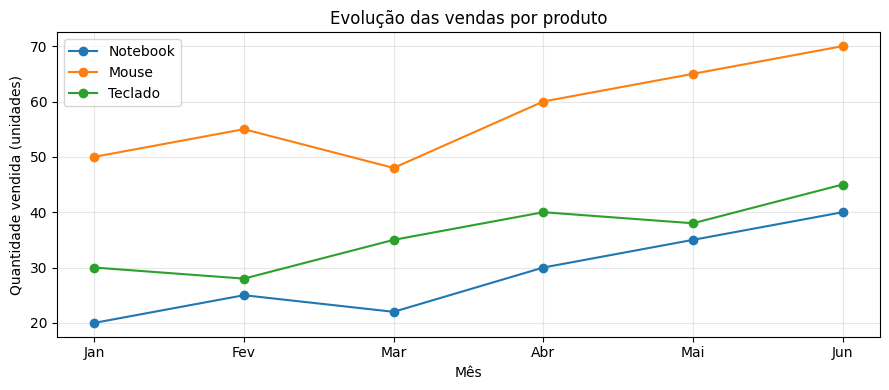

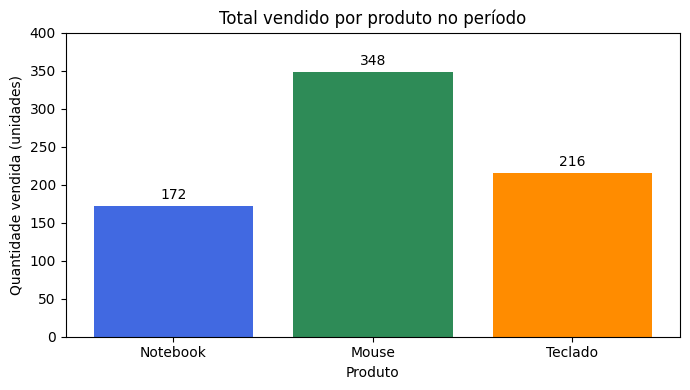

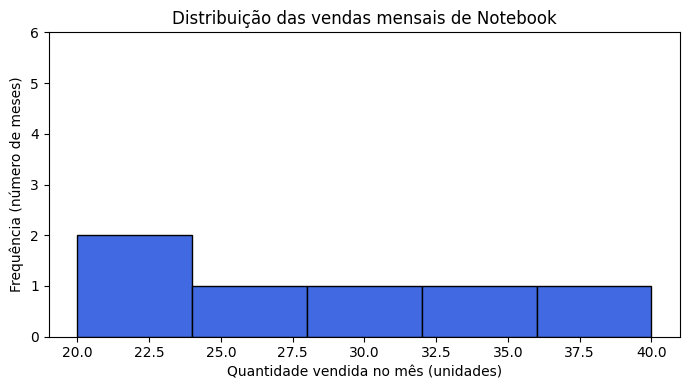


RESUMO POR PRODUTO
          Total vendido Mês de maior venda  Quantidade no melhor mês
Notebook            172                Jun                        40
Mouse               348                Jun                        70
Teclado             216                Jun                        45

O produto com maior volume total foi Mouse, com 348 unidades.

COMPARAÇÃO ENTRE O INÍCIO E O FIM DO PERÍODO
          Vendas em janeiro  Vendas em junho  \
Produto                                        
Notebook                 20               40   
Mouse                    50               70   
Teclado                  30               45   

          Crescimento de janeiro a junho (%)  
Produto                                       
Notebook                               100.0  
Mouse                                   40.0  
Teclado                                 50.0  

Conclusão: todos os produtos terminaram junho com vendas superiores às de janeiro. O gráfico de linhas mostra uma tend

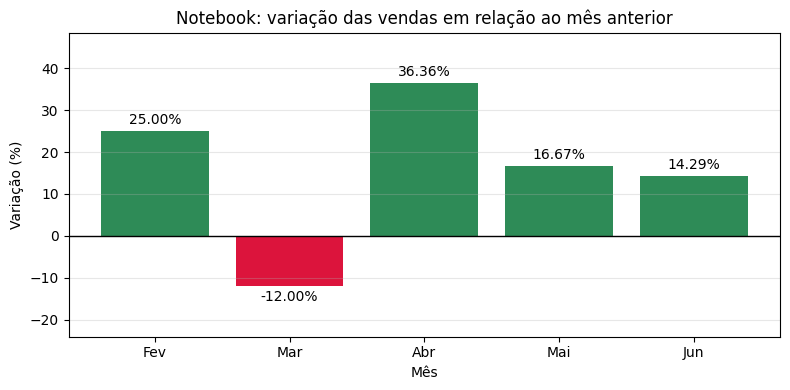


ANÁLISE DA VISUALIZAÇÃO EXTRA
O maior crescimento mensal de Notebook ocorreu em Abr, com aumento de 36.36% em relação ao mês anterior.
Meses com queda nas vendas: ['Mar']

Escolhi o gráfico de barras porque ele permite comparar a intensidade das variações mensais. As barras verdes indicam crescimento e as vermelhas indicam queda. Assim, podemos distinguir o mês com maior crescimento percentual do mês com maior quantidade vendida.


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Dados iniciais
dados = {
    "Mes": ["Jan", "Fev", "Mar", "Abr", "Mai", "Jun"],
    "Notebook": [20, 25, 22, 30, 35, 40],
    "Mouse": [50, 55, 48, 60, 65, 70],
    "Teclado": [30, 28, 35, 40, 38, 45]
}

df = pd.DataFrame(dados)
produtos = ["Notebook", "Mouse", "Teclado"]

# Matriz numérica para os cálculos com NumPy
vendas = df[produtos].to_numpy()

# ==================================================
# 1. EXPLORAÇÃO
# ==================================================
print("PRIMEIRAS LINHAS")
print(df.head())

print("\nDIMENSÕES")
print(f"Linhas: {df.shape[0]}")
print(f"Colunas: {df.shape[1]}")

print("\nESTATÍSTICAS DESCRITIVAS")
print(df.describe().round(2))

# ==================================================
# 2. INDICADORES CALCULADOS COM NUMPY
# ==================================================
indicadores = pd.DataFrame({
    "Produto": produtos,
    "Média mensal": np.mean(vendas, axis=0),
    "Maior venda mensal": np.max(vendas, axis=0),
    "Menor venda mensal": np.min(vendas, axis=0)
}).set_index("Produto")

print("\nINDICADORES POR PRODUTO")
print(indicadores.round(2))

# ==================================================
# 3. EVOLUÇÃO TEMPORAL — GRÁFICO DE LINHAS
# ==================================================
plt.figure(figsize=(9, 4))

plt.plot(df["Mes"], vendas, marker="o")
plt.title("Evolução das vendas por produto")
plt.xlabel("Mês")
plt.ylabel("Quantidade vendida (unidades)")
plt.legend(produtos)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# ==================================================
# 4. COMPARAÇÃO — TOTAL VENDIDO POR PRODUTO
# ==================================================
totais = pd.Series(
    np.sum(vendas, axis=0),
    index=produtos,
    name="Total vendido"
)

fig, ax = plt.subplots(figsize=(7, 4))

barras = ax.bar(
    totais.index,
    totais.values,
    color=["royalblue", "seagreen", "darkorange"]
)

ax.bar_label(barras, padding=3)
ax.set_title("Total vendido por produto no período")
ax.set_xlabel("Produto")
ax.set_ylabel("Quantidade vendida (unidades)")
ax.set_ylim(0, totais.max() * 1.15)

plt.tight_layout()
plt.show()

# ==================================================
# 5. DISTRIBUIÇÃO — HISTOGRAMA DE NOTEBOOK
# ==================================================
produto_escolhido = "Notebook"

plt.figure(figsize=(7, 4))

plt.hist(
    df[produto_escolhido],
    bins=5,
    color="royalblue",
    edgecolor="black"
)

plt.title(f"Distribuição das vendas mensais de {produto_escolhido}")
plt.xlabel("Quantidade vendida no mês (unidades)")
plt.ylabel("Frequência (número de meses)")
plt.yticks(np.arange(0, len(df) + 1))

plt.tight_layout()
plt.show()

# ==================================================
# 6. INTERPRETAÇÃO
# ==================================================
produto_lider = totais.idxmax()

# Usa os meses como índice para identificar o mês de maior venda.
vendas_por_mes = df.set_index("Mes")[produtos]

resumo = pd.DataFrame({
    "Total vendido": totais,
    "Mês de maior venda": vendas_por_mes.idxmax(),
    "Quantidade no melhor mês": vendas_por_mes.max()
})

print("\nRESUMO POR PRODUTO")
print(resumo)

print(
    f"\nO produto com maior volume total foi {produto_lider}, "
    f"com {totais[produto_lider]} unidades."
)

# Compara o primeiro e o último mês de cada produto.
crescimento_periodo = (
    (vendas[-1] - vendas[0]) / vendas[0]
) * 100

comparacao = pd.DataFrame({
    "Produto": produtos,
    "Vendas em janeiro": vendas[0],
    "Vendas em junho": vendas[-1],
    "Crescimento de janeiro a junho (%)": crescimento_periodo
}).set_index("Produto")

print("\nCOMPARAÇÃO ENTRE O INÍCIO E O FIM DO PERÍODO")
print(comparacao.round(2))

print(
    "\nConclusão: todos os produtos terminaram junho com vendas "
    "superiores às de janeiro. O gráfico de linhas mostra uma "
    "tendência geral de crescimento, mas também quedas em alguns "
    "meses. O gráfico de barras permite identificar o produto "
    "com maior volume acumulado."
)

print(
    "\nO histograma mostra como os seis valores mensais de Notebook "
    "se distribuem por faixas de quantidade. Como há somente seis "
    "observações, ele não permite concluir um padrão estável "
    "para períodos futuros."
)

# ==================================================
# 7. VISUALIZAÇÃO EXTRA — VARIAÇÃO PERCENTUAL
# Pergunta: em qual mês Notebook mais cresceu em relação
# ao mês imediatamente anterior?
# ==================================================
vendas_notebook = df[produto_escolhido].to_numpy(dtype=float)

# np.diff calcula a diferença entre meses consecutivos.
variacao_percentual = (
    np.diff(vendas_notebook) / vendas_notebook[:-1]
) * 100

# Janeiro não tem mês anterior disponível para comparação.
meses_comparacao = df["Mes"].to_numpy()[1:]

cores = np.where(
    variacao_percentual >= 0,
    "seagreen",
    "crimson"
)

fig, ax = plt.subplots(figsize=(8, 4))

barras = ax.bar(
    meses_comparacao,
    variacao_percentual,
    color=cores
)

ax.bar_label(barras, fmt="%.2f%%", padding=3)
ax.axhline(0, color="black", linewidth=1)

ax.set_title("Notebook: variação das vendas em relação ao mês anterior")
ax.set_xlabel("Mês")
ax.set_ylabel("Variação (%)")
ax.margins(y=0.25)
ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

indice_maior_crescimento = np.argmax(variacao_percentual)

print("\nANÁLISE DA VISUALIZAÇÃO EXTRA")
print(
    f"O maior crescimento mensal de {produto_escolhido} ocorreu "
    f"em {meses_comparacao[indice_maior_crescimento]}, com aumento "
    f"de {variacao_percentual[indice_maior_crescimento]:.2f}% "
    "em relação ao mês anterior."
)

print(
    "Meses com queda nas vendas:",
    meses_comparacao[variacao_percentual < 0]
)

print(
    "\nEscolhi o gráfico de barras porque ele permite comparar "
    "a intensidade das variações mensais. As barras verdes indicam "
    "crescimento e as vermelhas indicam queda. Assim, podemos "
    "distinguir o mês com maior crescimento percentual do mês "
    "com maior quantidade vendida."
)